# 架构
CLIP 的核心思想是通过**对比学习**将图像和文本映射到同一特征空间，实现零样本分类能力。

CLIP 由两个编码器组成：

- **图像编码器**：Vision Transformer (ViT) 或 ResNet
- **文本编码器**：Transformer 编码器
- 两者输出通过线性投影映射到同一维度的特征空间，计算余弦相似度进行对比学习

整个模型没有分类头，也没有生成式解码，仅通过对比损失完成端到端训练，这是它能实现零样本分类的核心基础。

In [ ]:
# 1.导入依赖
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
from typing import Tuple, Optional

# 2.图像编码器（Vision Transformer）
class PatchEmbedding(nn.Module):
    """将图像切分为patch并做嵌入"""
    def __init__(self, img_size: int = 224, patch_size: int = 32,
                 in_channels: int = 3, embed_dim: int = 768):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2

        self.proj = nn.Conv2d(in_channels, embed_dim,
                              kernel_size=patch_size, stride=patch_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [B, 3, H, W] -> [B, embed_dim, H/patch, W/patch]（batch、通道、高、宽）
        x = self.proj(x)
        # 展平: [B, embed_dim, num_patches] -> [B, num_patches, embed_dim]
        x = x.flatten(2).transpose(1, 2)
        return x


class VisionTransformer(nn.Module):
    """ViT 图像编码器"""
    def __init__(self, img_size: int = 224, patch_size: int = 32,
                 in_channels: int = 3, embed_dim: int = 768,
                 depth: int = 12, num_heads: int = 12,
                 mlp_ratio: float = 4.0, dropout: float = 0.0):
        super().__init__()
        self.embed_dim = embed_dim

        # Patch嵌入
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        num_patches = self.patch_embed.num_patches

        # 分类token + 位置编码
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(dropout)

        # Transformer编码器层：标准 Transformer 编码器结构：多头自注意力 + 前馈网络（MLP），每层都带残差连接和 LayerNorm
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads,
            dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=dropout, activation='gelu', batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=depth)

        self.norm = nn.LayerNorm(embed_dim)

        # 初始化
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B = x.shape[0]

        # Patch嵌入
        x = self.patch_embed(x)

        # 拼接cls token
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)

        # 加位置编码
        x = x + self.pos_embed
        x = self.pos_drop(x)

        # Transformer编码
        x = self.transformer(x)
        x = self.norm(x)

        # 取cls token作为图像特征
        return x[:, 0]

# 3.文本编码器（Transformer）
class TextTransformer(nn.Module):
    """
    文本编码器 - 基于Transformer
    自注意力是单向的（带因果掩码），而非图像编码器的双向注意力
    全局表征取句子结束符（eot）的特征，而非额外的 cls token
    """
    def __init__(self, vocab_size: int = 49408, context_length: int = 77,
                 embed_dim: int = 512, transformer_width: int = 512,
                 transformer_heads: int = 8, transformer_layers: int = 12):
        super().__init__()
        self.context_length = context_length
        self.transformer_width = transformer_width

        # Token嵌入 + 位置编码
        self.token_embedding = nn.Embedding(vocab_size, transformer_width) # 词嵌入：将每个 token id 映射为维度为 `transformer_width` 的向量
        self.positional_embedding = nn.Parameter(
            torch.empty(self.context_length, transformer_width)
        ) # 位置编码：可学习参数，长度固定为 `context_length=77`（CLIP 原文固定最大文本长度 77）

        # Transformer编码器
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=transformer_width, nhead=transformer_heads,
            dim_feedforward=transformer_width * 4,
            dropout=0.0, activation='gelu', batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=transformer_layers)

        self.ln_final = nn.LayerNorm(transformer_width)

        # 文本投影头
        self.text_projection = nn.Parameter(torch.empty(transformer_width, embed_dim))

        # 初始化
        nn.init.normal_(self.token_embedding.weight, std=0.02)
        nn.init.normal_(self.positional_embedding, std=0.01)
        nn.init.normal_(self.text_projection, std=transformer_width ** -0.5)

    def forward(self, text: torch.Tensor) -> torch.Tensor:
        # text: [B, context_length] token ids
        x = self.token_embedding(text)  # [B, L, D]
        x = x + self.positional_embedding.unsqueeze(0)

        # 因果掩码（仅看前面的token）
        mask = nn.Transformer.generate_square_subsequent_mask(self.context_length, device=x.device)

        x = self.transformer(x, mask=mask, is_causal=True)
        x = self.ln_final(x)

        # 取eos位置的特征（CLIP用<eot> token位置）
        # 这里简化取序列最后一个token
        '''
        这是 CLIP 官方实现的经典技巧：
        CLIP 词汇表中，`<eot>`（句子结束符）的 id 是 49407，是词汇表中数值最大的 token；填充符 `<pad>` 的 id 是 0，普通词汇 id 都小于 eot。
        对 token id 序列取 `argmax`，得到的索引就是 eot token 的位置，也就是句子的实际结束位置。
        取该位置的输出特征作为整个句子的全局表征，替代 cls token 的作用。
        '''
        x = x[torch.arange(x.shape[0]), text.argmax(dim=-1)] @ self.text_projection

        return x

# 4.CLIP主体
class CLIP(nn.Module):
    def __init__(self,
                 # 图像编码器参数
                 image_size: int = 224,
                 patch_size: int = 32,
                 vision_embed_dim: int = 768,
                 vision_layers: int = 12,
                 vision_heads: int = 12,
                 # 文本编码器参数
                 vocab_size: int = 49408,
                 context_length: int = 77,
                 transformer_width: int = 512,
                 transformer_heads: int = 8,
                 transformer_layers: int = 12,
                 # 公共特征维度
                 embed_dim: int = 512):
        super().__init__()

        # 图像编码器
        self.visual = VisionTransformer(
            img_size=image_size,
            patch_size=patch_size,
            embed_dim=vision_embed_dim,
            depth=vision_layers,
            num_heads=vision_heads
        )

        # 图像投影头
        self.image_projection = nn.Linear(vision_embed_dim, embed_dim, bias=False)

        # 文本编码器
        self.transformer = TextTransformer(
            vocab_size=vocab_size,
            context_length=context_length,
            embed_dim=embed_dim,
            transformer_width=transformer_width,
            transformer_heads=transformer_heads,
            transformer_layers=transformer_layers
        )

        # 可学习温度参数 (log scale)
        self.logit_scale = nn.Parameter(torch.ones([]) * np.log(1 / 0.07))

    def encode_image(self, image: torch.Tensor) -> torch.Tensor:
        """编码图像 -> 归一化特征"""
        x = self.visual(image)
        x = self.image_projection(x)
        return F.normalize(x, dim=-1)

    def encode_text(self, text: torch.Tensor) -> torch.Tensor:
        """编码文本 -> 归一化特征"""
        x = self.transformer(text)
        return F.normalize(x, dim=-1)

    def forward(self, image: torch.Tensor, text: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        前向传播，返回图文相似度矩阵
        Returns:
            logits_per_image: [B, B] 图像对文本的相似度
            logits_per_text: [B, B] 文本对图像的相似度
        """
        image_features = self.encode_image(image)
        text_features = self.encode_text(text)

        # 温度缩放的余弦相似度
        logit_scale = self.logit_scale.exp()
        logits_per_image = logit_scale * image_features @ text_features.t()
        logits_per_text = logits_per_image.t()

        return logits_per_image, logits_per_text

# 5.对比损失函数
def clip_loss(logits_per_image: torch.Tensor, logits_per_text: torch.Tensor) -> torch.Tensor:
    """CLIP 对称对比损失"""
    batch_size = logits_per_image.shape[0]
    labels = torch.arange(batch_size, device=logits_per_image.device)

    loss_i = F.cross_entropy(logits_per_image, labels)
    loss_t = F.cross_entropy(logits_per_text, labels)

    return (loss_i + loss_t) / 2

# 6.简单分词器
class SimpleTokenizer:
    """简化版BPE分词器，实际使用请用CLIP官方的bpe分词"""
    def __init__(self, context_length: int = 77):
        self.context_length = context_length
        self.vocab_size = 49408
        self.sot_token = 49406  # <start_of_text>
        self.eot_token = 49407  # <end_of_text>

    def encode(self, text: str) -> list:
        """极简实现：字符级编码，仅用于演示"""
        tokens = [self.sot_token]
        for c in text.lower()[:self.context_length - 2]:
            # 简单映射到词汇表
            tokens.append(ord(c) % (self.vocab_size - 2) + 1)
        tokens.append(self.eot_token)

        # padding
        while len(tokens) < self.context_length:
            tokens.append(0)
        return tokens[:self.context_length]

    def __call__(self, texts):
        if isinstance(texts, str):
            texts = [texts]
        return torch.tensor([self.encode(t) for t in texts], dtype=torch.long)

# 7.模拟数据集
class DummyClipDataset(Dataset):
    """模拟图文对数据集，用于测试模型能否跑通"""
    def __init__(self, num_samples: int = 1000, img_size: int = 224):
        self.num_samples = num_samples
        self.img_size = img_size
        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize((0.48145466, 0.4578275, 0.40821073),
                               (0.26862954, 0.26130258, 0.27577711))
        ])
        self.tokenizer = SimpleTokenizer()
        self.texts = [f"a photo of object {i}" for i in range(num_samples)]

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        # 随机图像
        image = torch.randn(3, self.img_size, self.img_size)
        text = self.tokenizer.encode(self.texts[idx])
        return image, torch.tensor(text, dtype=torch.long)

# 8.训练循环示例
def train_clip():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    # 初始化模型 (ViT-B/32 配置)
    model = CLIP(
        image_size=224,
        patch_size=32,
        vision_embed_dim=768,
        vision_layers=12,
        vision_heads=12,
        embed_dim=512,
        transformer_width=512,
        transformer_heads=8,
        transformer_layers=12
    ).to(device)

    # 数据集
    dataset = DummyClipDataset(num_samples=128)
    dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

    # 优化器
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.1)

    # 训练
    model.train()
    num_epochs = 5

    for epoch in range(num_epochs):
        total_loss = 0.0
        for batch_idx, (images, texts) in enumerate(dataloader):
            images = images.to(device)
            texts = texts.to(device)

            optimizer.zero_grad()

            logits_per_image, logits_per_text = model(images, texts)
            loss = clip_loss(logits_per_image, logits_per_text)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(dataloader)
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}, "
              f"Temperature: {model.logit_scale.exp().item():.4f}")

    print("训练完成！")
    return model

# 9.零样本分类推理示例
def zero_shot_classification_example(model):
    """零样本分类演示"""
    device = next(model.parameters()).device
    tokenizer = SimpleTokenizer()

    # 类别文本描述
    class_names = ["cat", "dog", "bird", "car"]
    text_prompts = [f"a photo of a {name}" for name in class_names]

    # 编码文本
    text_tokens = tokenizer(text_prompts).to(device)
    text_features = model.encode_text(text_tokens)

    # 模拟一张测试图
    test_image = torch.randn(1, 3, 224, 224).to(device)
    image_features = model.encode_image(test_image)

    # 计算相似度
    similarity = (100.0 * image_features @ text_features.T).softmax(dim=-1)

    print("\n零样本分类结果:")
    for i, name in enumerate(class_names):
        print(f"  {name}: {similarity[0, i].item()*100:.2f}%")

# 10.主函数
if __name__ == "__main__":
    # 训练
    model = train_clip()

    # 零样本推理
    model.eval()
    with torch.no_grad():
        zero_shot_classification_example(model)


Using device: cpu
Epoch [1/5], Loss: 3.4896, Temperature: 14.2699
Epoch [2/5], Loss: 3.4657, Temperature: 14.2603
Epoch [3/5], Loss: 3.4657, Temperature: 14.2526
Epoch [4/5], Loss: 3.4657, Temperature: 14.2460
Epoch [5/5], Loss: 3.4657, Temperature: 14.2401
训练完成！

零样本分类结果:
  cat: 25.03%
  dog: 25.00%
  bird: 24.93%
  car: 25.04%


# 官方示例

[INFO] 使用设备: cuda
[INFO] 正在加载模型: openai/clip-vit-base-patch32 ...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[INFO] 模型加载完成
[INFO] 下载图像: http://images.cocodataset.org/val2017/000000039769.jpg
[INFO] 图像尺寸: (640, 480)

========== 分类结果 ==========
  0.9850  a photo of a cat
  0.0075  a photo of a person
  0.0051  a photo of a dog
  0.0022  a photo of a car
  0.0002  a photo of a tree

[结论] 最匹配标签: 'a photo of a cat' (置信度 0.9850)


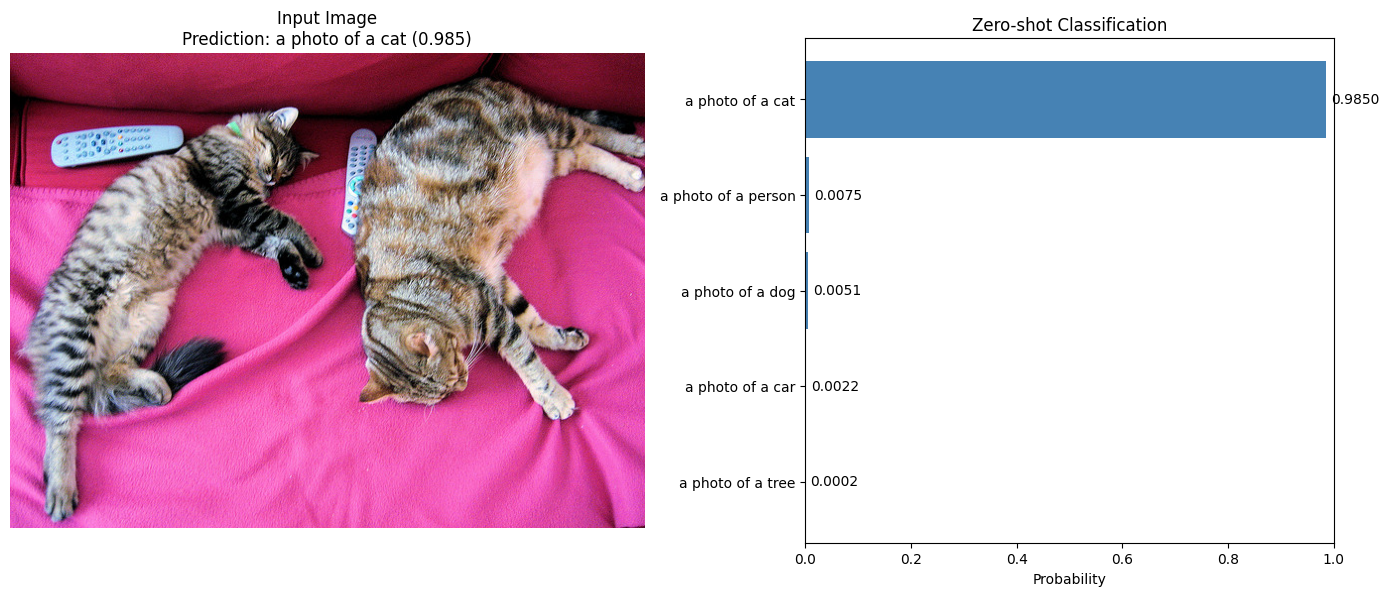

In [ ]:
"""
CLIP 零样本图像分类完整示例（带图片展示）
依赖: pip install torch transformers pillow requests matplotlib
运行: python clip_demo_show.py
"""

import requests
import torch
import matplotlib.pyplot as plt
from PIL import Image
from transformers import AutoModel, AutoProcessor

# -----------------------------
# 1. 基础配置
# -----------------------------
MODEL_NAME = "openai/clip-vit-base-patch32"
IMAGE_URL = "http://images.cocodataset.org/val2017/000000039769.jpg"

CANDIDATE_LABELS = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a tree",
    "a photo of a person",
]

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[INFO] 使用设备: {device}")

# -----------------------------
# 2. 加载模型与处理器
# -----------------------------
print(f"[INFO] 正在加载模型: {MODEL_NAME} ...")
model = AutoModel.from_pretrained(MODEL_NAME).to(device)
processor = AutoProcessor.from_pretrained(MODEL_NAME)
model.eval()
print("[INFO] 模型加载完成")

# -----------------------------
# 3. 读取图像
# -----------------------------
print(f"[INFO] 下载图像: {IMAGE_URL}")
image = Image.open(requests.get(IMAGE_URL, stream=True).raw).convert("RGB")
print(f"[INFO] 图像尺寸: {image.size}")

# -----------------------------
# 4. 预处理 + 前向计算
# -----------------------------
inputs = processor(
    text=CANDIDATE_LABELS,
    images=image,
    return_tensors="pt",
    padding=True,
).to(device)

with torch.no_grad():
    outputs = model(**inputs)

logits_per_image = outputs.logits_per_image          # (1, 文本数量)
probs = logits_per_image.softmax(dim=1)[0]           # (文本数量,)

# -----------------------------
# 5. 打印结果
# -----------------------------
print("\n========== 分类结果 ==========")
results = sorted(
    zip(CANDIDATE_LABELS, probs.tolist()),
    key=lambda x: x[1],
    reverse=True,
)
for label, prob in results:
    print(f"{prob:8.4f}  {label}")

best_label, best_prob = results[0]
print(f"\n[结论] 最匹配标签: '{best_label}' (置信度 {best_prob:.4f})")

# -----------------------------
# 6. 可视化：左图右柱状图
# -----------------------------
fig, (ax_img, ax_bar) = plt.subplots(
    1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.2, 1]}
)

# 左：显示图片
ax_img.imshow(image)
ax_img.axis("off")
ax_img.set_title(f"Input Image\nPrediction: {best_label} ({best_prob:.3f})", fontsize=12)

# 右：横向柱状图（按概率从高到低）
labels_sorted = [r[0] for r in results]
probs_sorted = [r[1] for r in results]
y_pos = range(len(labels_sorted))[::-1]  # 最高的放最上面

bars = ax_bar.barh(list(y_pos), probs_sorted, color="steelblue")
ax_bar.set_yticks(list(y_pos))
ax_bar.set_yticklabels(labels_sorted)
ax_bar.set_xlabel("Probability")
ax_bar.set_xlim(0, 1)
ax_bar.set_title("Zero-shot Classification", fontsize=12)

# 在柱状图末端标注数值
for bar, p in zip(bars, probs_sorted):
    ax_bar.text(
        bar.get_width() + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{p:.4f}",
        va="center",
        fontsize=10,
    )

plt.tight_layout()

# 如需保存图片，取消下面这行的注释
# plt.savefig("clip_result.png", dpi=150, bbox_inches="tight")

plt.show()

# 示例


Running on device: cuda


100%|██████████| 170M/170M [52:44<00:00, 53.9kB/s]



Epoch [1/50]


Evaluating: 100%|██████████| 16/16 [00:00<00:00, 37.98it/s]


Train Loss: 4.1499
Zero-Shot Acc: 0.1190
Temperature: 14.1743

Epoch [2/50]


Evaluating: 100%|██████████| 16/16 [00:00<00:00, 26.56it/s]


... (93 outputs left out)

Evaluating: 100%|██████████| 16/16 [00:00<00:00, 35.87it/s]


Train Loss: 2.3603
Zero-Shot Acc: 0.5560
Temperature: 12.8813

Epoch [50/50]


Evaluating: 100%|██████████| 16/16 [00:00<00:00, 36.65it/s]


Train Loss: 2.3674
Zero-Shot Acc: 0.5570
Temperature: 12.8814


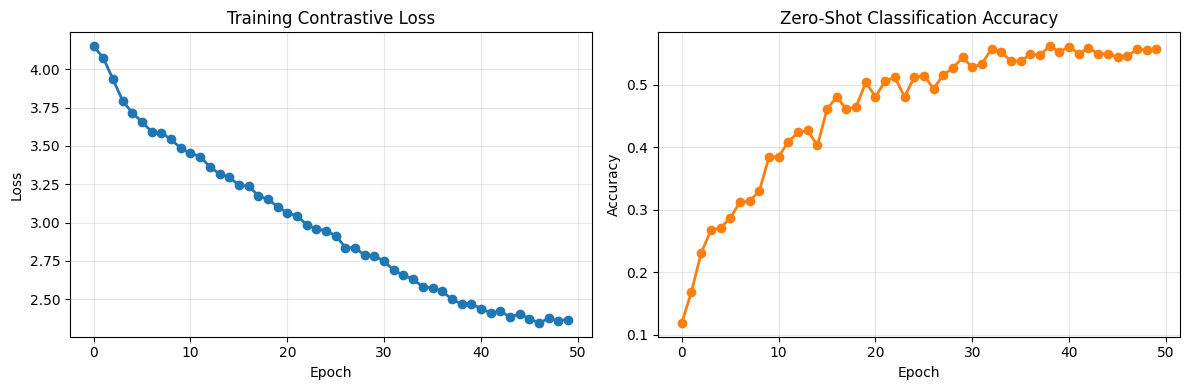


训练完成！曲线已保存为 clip_training_curve.png


Building similarity matrix: 100%|██████████| 16/16 [00:00<00:00, 32.48it/s]


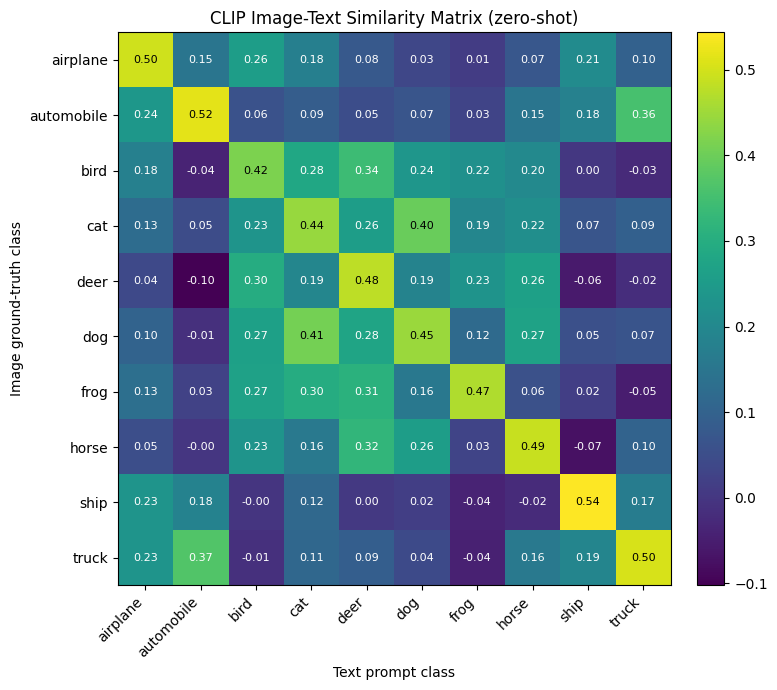

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np
from typing import Tuple
import random


def stratified_subset(dataset, num_per_class, num_classes=10, seed=42):
    """从每个类别中随机抽取 num_per_class 张，类别均衡"""
    rng = random.Random(seed)
    targets = np.array(dataset.targets)
    indices = []
    for c in range(num_classes):
        cls_idx = np.where(targets == c)[0].tolist()
        rng.shuffle(cls_idx)
        indices.extend(cls_idx[:num_per_class])
    return Subset(dataset, indices)


class PatchEmbedding(nn.Module):
    def __init__(self, img_size: int = 32, patch_size: int = 4,
                 in_channels: int = 3, embed_dim: int = 256):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2
        self.proj = nn.Conv2d(in_channels, embed_dim,
                              kernel_size=patch_size, stride=patch_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.proj(x)
        x = x.flatten(2).transpose(1, 2)
        return x


class VisionTransformer(nn.Module):
    def __init__(self, img_size: int = 32, patch_size: int = 4,
                 in_channels: int = 3, embed_dim: int = 256,
                 depth: int = 6, num_heads: int = 8,
                 mlp_ratio: float = 4.0, dropout: float = 0.0):
        super().__init__()
        self.embed_dim = embed_dim
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        num_patches = self.patch_embed.num_patches

        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads,
            dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=dropout, activation='gelu', batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=depth)
        self.norm = nn.LayerNorm(embed_dim)

        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B = x.shape[0]
        x = self.patch_embed(x)
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)
        x = x + self.pos_embed
        x = self.pos_drop(x)
        x = self.transformer(x)
        x = self.norm(x)
        return x[:, 0]


class TextTransformer(nn.Module):
    def __init__(self, vocab_size: int = 49408, context_length: int = 77,
                 embed_dim: int = 128, transformer_width: int = 128,
                 transformer_heads: int = 4, transformer_layers: int = 6):
        super().__init__()
        self.context_length = context_length
        self.transformer_width = transformer_width

        self.token_embedding = nn.Embedding(vocab_size, transformer_width)
        self.positional_embedding = nn.Parameter(
            torch.empty(self.context_length, transformer_width)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=transformer_width, nhead=transformer_heads,
            dim_feedforward=transformer_width * 4,
            dropout=0.0, activation='gelu', batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=transformer_layers)

        self.ln_final = nn.LayerNorm(transformer_width)
        self.text_projection = nn.Parameter(torch.empty(transformer_width, embed_dim))

        nn.init.normal_(self.token_embedding.weight, std=0.02)
        nn.init.normal_(self.positional_embedding, std=0.01)
        nn.init.normal_(self.text_projection, std=transformer_width ** -0.5)

    def forward(self, text: torch.Tensor) -> torch.Tensor:
        x = self.token_embedding(text)
        x = x + self.positional_embedding.unsqueeze(0)

        mask = nn.Transformer.generate_square_subsequent_mask(
            self.context_length, device=x.device
        )
        x = self.transformer(x, mask=mask, is_causal=True)
        x = self.ln_final(x)

        # EOT 位置池化（EOT token id 是 vocab 里最大，argmax 恰好能找到它）
        x = x[torch.arange(x.shape[0]), text.argmax(dim=-1)] @ self.text_projection
        return x


class CLIP(nn.Module):
    def __init__(self,
                 image_size: int = 32,
                 patch_size: int = 4,
                 vision_embed_dim: int = 256,
                 vision_layers: int = 6,
                 vision_heads: int = 8,
                 vocab_size: int = 49408,
                 context_length: int = 77,
                 transformer_width: int = 128,
                 transformer_heads: int = 4,
                 transformer_layers: int = 6,
                 embed_dim: int = 128):
        super().__init__()

        self.visual = VisionTransformer(
            img_size=image_size, patch_size=patch_size,
            embed_dim=vision_embed_dim, depth=vision_layers, num_heads=vision_heads
        )
        self.image_projection = nn.Linear(vision_embed_dim, embed_dim, bias=False)

        self.transformer = TextTransformer(
            vocab_size=vocab_size, context_length=context_length,
            embed_dim=embed_dim, transformer_width=transformer_width,
            transformer_heads=transformer_heads, transformer_layers=transformer_layers
        )

        self.logit_scale = nn.Parameter(torch.ones([]) * np.log(1 / 0.07))

    def encode_image(self, image: torch.Tensor) -> torch.Tensor:
        x = self.visual(image)
        x = self.image_projection(x)
        return F.normalize(x, dim=-1)

    def encode_text(self, text: torch.Tensor) -> torch.Tensor:
        x = self.transformer(text)
        return F.normalize(x, dim=-1)

    def forward(self, image: torch.Tensor, text: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        image_features = self.encode_image(image)
        text_features = self.encode_text(text)

        logit_scale = self.logit_scale.exp()
        logits_per_image = logit_scale * image_features @ text_features.t()
        logits_per_text = logits_per_image.t()

        return logits_per_image, logits_per_text


def clip_loss(logits_per_image: torch.Tensor, logits_per_text: torch.Tensor) -> torch.Tensor:
    batch_size = logits_per_image.shape[0]
    labels = torch.arange(batch_size, device=logits_per_image.device)
    loss_i = F.cross_entropy(logits_per_image, labels)
    loss_t = F.cross_entropy(logits_per_text, labels)
    return (loss_i + loss_t) / 2


class SimpleTokenizer:
    def __init__(self, context_length: int = 77):
        self.context_length = context_length
        self.vocab_size = 49408
        self.sot_token = 49406
        self.eot_token = 49407

    def encode(self, text: str) -> list:
        tokens = [self.sot_token]
        for c in text.lower()[:self.context_length - 2]:
            tokens.append(ord(c) % (self.vocab_size - 2) + 1)
        tokens.append(self.eot_token)
        while len(tokens) < self.context_length:
            tokens.append(0)
        return tokens[:self.context_length]

    def __call__(self, texts):
        if isinstance(texts, str):
            texts = [texts]
        return torch.tensor([self.encode(t) for t in texts], dtype=torch.long)


class CIFAR10ClipDataset(Dataset):
    """把 (image, label) 包装成 (image_tensor, text_tokens)"""
    def __init__(self, raw_dataset, class_names, tokenizer, transform=None):
        self.raw_dataset = raw_dataset
        self.class_names = class_names
        self.tokenizer = tokenizer
        self.transform = transform

    def __len__(self):
        return len(self.raw_dataset)

    def __getitem__(self, idx):
        image, label = self.raw_dataset[idx]
        if self.transform is not None:
            image = self.transform(image)
        text = f"a photo of a {self.class_names[label]}"
        text_tokens = self.tokenizer.encode(text)
        return image, torch.tensor(text_tokens, dtype=torch.long)


def train_one_epoch(model, dataloader, optimizer, device, criterion):
    model.train()
    total_loss = 0.0
    for images, texts in tqdm(dataloader, desc="Training"):
        images = images.to(device)
        texts = texts.to(device)

        optimizer.zero_grad()
        logits_per_image, logits_per_text = model(images, texts)
        loss = criterion(logits_per_image, logits_per_text)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
    return total_loss / len(dataloader.dataset)


def zero_shot_evaluate(model, test_loader, class_names, tokenizer, device):
    model.eval()
    text_prompts = [f"a photo of a {name}" for name in class_names]
    text_tokens = tokenizer(text_prompts).to(device)

    with torch.no_grad():
        text_features = model.encode_text(text_tokens)  # [C, D]

    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Evaluating"):
            images = images.to(device)
            labels = labels.to(device)

            image_features = model.encode_image(images)
            similarity = image_features @ text_features.T
            preds = similarity.argmax(dim=-1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return correct / total


def plot_results(train_losses, test_accs):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(train_losses, marker='o', color='#1f77b4', linewidth=2)
    ax1.set_title('Training Contrastive Loss', fontsize=12)
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.grid(True, alpha=0.3)

    ax2.plot(test_accs, marker='o', color='#ff7f0e', linewidth=2)
    ax2.set_title('Zero-Shot Classification Accuracy', fontsize=12)
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('clip_training_curve.png', dpi=150, bbox_inches='tight')
    plt.show()

def visualize_similarity_matrix(model, test_loader, class_names, tokenizer, device, save_path="clip_similarity_heatmap.png"):
    """绘制 10x10 类平均图文相似度矩阵：行为图像真实类，列为文本提示类"""
    model.eval()
    with torch.no_grad():
        text_tokens = tokenizer([f"a photo of a {n}" for n in class_names]).to(device)
        text_features = model.encode_text(text_tokens)          # [C, D]

        C = len(class_names)
        sim_sum = torch.zeros(C, C, device=device)
        count = torch.zeros(C, device=device)

        for images, labels in tqdm(test_loader, desc="Building similarity matrix"):
            images, labels = images.to(device), labels.to(device)
            img_feat = model.encode_image(images)               # [B, D]
            sim = img_feat @ text_features.T                     # [B, C]
            for i in range(C):
                mask = labels == i
                if mask.any():
                    sim_sum[i] += sim[mask].sum(0)
                    count[i] += mask.sum().item()

        sim_matrix = (sim_sum / count.unsqueeze(1)).cpu().numpy()

    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(sim_matrix, cmap="viridis")
    ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
    ax.set_xlabel("Text prompt class"); ax.set_ylabel("Image ground-truth class")
    ax.set_title("CLIP Image-Text Similarity Matrix (zero-shot)")
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax.text(j, i, f"{sim_matrix[i, j]:.2f}", ha="center", va="center",
                    color="white" if sim_matrix[i, j] < sim_matrix.max() * 0.7 else "black", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

def main():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Running on device: {device}")

    CIFAR10_CLASSES = [
        'airplane', 'automobile', 'bird', 'cat', 'deer',
        'dog', 'frog', 'horse', 'ship', 'truck'
    ]

    # ---------- 模型配置 ----------
    model_config = {
        'image_size': 32,
        'patch_size': 4,
        'vision_embed_dim': 256,
        'vision_layers': 6,
        'vision_heads': 8,
        'vocab_size': 49408,
        'context_length': 77,
        'transformer_width': 128,
        'transformer_heads': 4,
        'transformer_layers': 6,
        'embed_dim': 128,
    }

    # ---------- 训练配置 ----------
    train_config = {
        'batch_size': 64,
        'lr': 3e-4,
        'weight_decay': 0.1,
        'num_epochs': 50,
        'train_per_class': 300,   # 3000 训练图
        'test_per_class': 100,    # 1000 测试图
        'num_workers': 2,         # notebook/Windows 报错时可先改 0
    }

    tokenizer = SimpleTokenizer(context_length=model_config['context_length'])

    transform_train = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465),
                             (0.2023, 0.1994, 0.2010)),
    ])
    transform_test = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465),
                             (0.2023, 0.1994, 0.2010)),
    ])

    # ========== 数据加载 ==========
    # train_raw：不带 transform，交给 CIFAR10ClipDataset 里的 transform_train
    train_raw = torchvision.datasets.CIFAR10(
        root='./data', train=True, download=True, transform=None
    )
    # test_raw：带上 transform_test，Subset 之后直接就是 tensor
    test_raw = torchvision.datasets.CIFAR10(
        root='./data', train=False, download=True, transform=transform_test
    )

    train_subset = stratified_subset(train_raw, train_config['train_per_class'])
    test_subset  = stratified_subset(test_raw,  train_config['test_per_class'])

    # train 侧：Subset 给的是 PIL，CIFAR10ClipDataset 做 ToTensor + 拼文本
    train_dataset = CIFAR10ClipDataset(
        train_subset, CIFAR10_CLASSES, tokenizer, transform=transform_train
    )

    # 调试时可以临时开这段自检
    # img, txt = train_dataset[0]
    # assert torch.is_tensor(img) and img.shape == (3, 32, 32), (type(img), getattr(img, 'shape', None))
    # img, lbl = test_subset[0]
    # assert torch.is_tensor(img) and img.shape == (3, 32, 32), (type(img), getattr(img, 'shape', None))

    train_loader = DataLoader(
        train_dataset,
        batch_size=train_config['batch_size'],
        shuffle=True,
        num_workers=train_config['num_workers'],
        drop_last=True,
    )
    # test_loader：样本已经是 (tensor, int)，zero_shot_evaluate 正好消费
    test_loader = DataLoader(
        test_subset,
        batch_size=train_config['batch_size'],
        shuffle=False,
        num_workers=train_config['num_workers'],
    )

    # ========== 模型 / 优化器 ==========
    model = CLIP(**model_config).to(device)
    criterion = clip_loss
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=train_config['lr'],
        weight_decay=train_config['weight_decay'],
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=train_config['num_epochs']
    )

    # ========== 训练循环 ==========
    train_losses = []
    test_accs = []

    for epoch in range(train_config['num_epochs']):
        print(f"\n{'='*50}")
        print(f"Epoch [{epoch + 1}/{train_config['num_epochs']}]")

        train_loss = train_one_epoch(model, train_loader, optimizer, device, criterion)
        test_acc = zero_shot_evaluate(model, test_loader, CIFAR10_CLASSES, tokenizer, device)

        scheduler.step()
        train_losses.append(train_loss)
        test_accs.append(test_acc)

        print(f"Train Loss: {train_loss:.4f}")
        print(f"Zero-Shot Acc: {test_acc:.4f}")
        print(f"Temperature: {model.logit_scale.exp().item():.4f}")

    plot_results(train_losses, test_accs)
    print("\n训练完成！曲线已保存为 clip_training_curve.png")
    visualize_similarity_matrix(model, test_loader, CIFAR10_CLASSES, tokenizer, device)
    return model, train_losses, test_accs


if __name__ == "__main__":
    model, losses, accs = main()